In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:

df = pd.read_csv("data/CleanedLifeInsurance.csv", encoding="utf-8-sig")
df.head()


,ENTRY AGE,SEX,POLICY TYPE 1,POLICY TYPE 2,POLICY TYPE 3,PAYMENT MODE,POLICY STATUS,BENEFIT,NON LAPSE GUARANTEED,SUBSTANDARD RISK,NUMBER OF ADVANCE PREMIUM,INITIAL BENEFIT,Full Benefit?,Policy Year (Decimal),Policy Year,Premium,Issue Date,is_lapse
0,36,F,1,1,A,Annually,Inforce,200000.0,NO NLG,0.0,0,0.0,N,8.000000,9,280.0,11-Aug,0
1,42,M,1,2,A,Annually,Inforce,100000.0,NO NLG,0.0,0,0.0,N,8.000000,9,200.0,11-Aug,0
2,40,M,2,3,A,Annually,Lapse,80000.0,NO NLG,0.0,0,0.0,N,8.000000,9,1289.0,11-Aug,1
3,39,M,1,2,A,Monthly,Lapse,100000.0,NO NLG,0.0,0,0.0,N,8.000000,9,216.0,11-Aug,1
4,44,M,1,2,A,Annually,Lapse,100000.0,NO NLG,0.0,0,0.0,N,7.916667,8,140.0,11-Sep,1


In [12]:
df["SUBSTD_RISK"] = df["SUBSTANDARD RISK"].apply(
    lambda x: "Y" if x > 0 else "N")
print(df["SUBSTD_RISK"].value_counts())

SUBSTD_RISK
N    184912
Y       648
Name: count, dtype: int64


In [13]:
lapse_summary = df.groupby("SUBSTD_RISK")["is_lapse"].agg(
    ["mean", "count"]
).reset_index()

lapse_summary.columns = ["SUBSTD_RISK", "lapse_rate", "count"]

print(lapse_summary)

  SUBSTD_RISK  lapse_rate   count
0           N    0.533319  184912
1           Y    0.382716     648


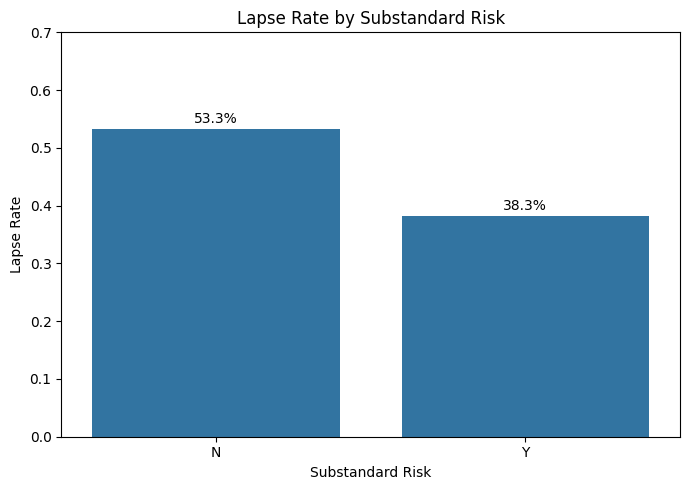

In [15]:
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=lapse_summary,
    x="SUBSTD_RISK",
    y="lapse_rate",
    order=["N", "Y"]
)

plt.title("Lapse Rate by Substandard Risk")
plt.xlabel("Substandard Risk")
plt.ylabel("Lapse Rate")
plt.ylim(0, 0.7)

# Add percentage labels
for bar in ax.patches:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.01,
        f"{height:.1%}",
        ha="center"
    )

plt.tight_layout()
plt.show()

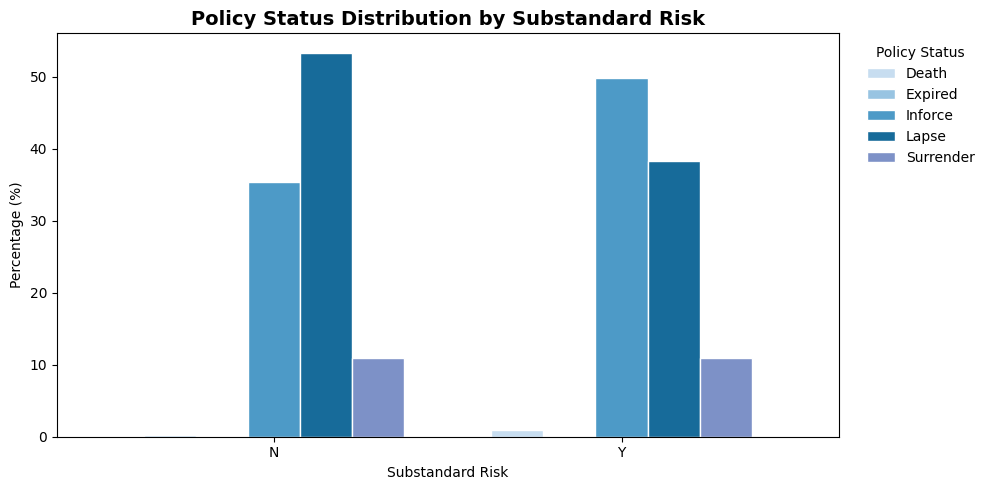

In [20]:
colors = {
    "Death": "#C7DDF0",      
    "Expired": "#98C4E2",    
    "Inforce": "#4D9AC7",    
    "Lapse": "#176B9A",     
    "Surrender": "#7D91C7" 
}

status_summary = pd.crosstab(
    df["substandard_risk"],
    df["POLICY STATUS"],
    normalize="index"
) * 100

ax = status_summary.plot(
    kind="bar",
    figsize=(10, 5),
    color=[colors[col] for col in status_summary.columns],
    edgecolor="white",
    width=0.75
)

plt.title("Policy Status Distribution by Substandard Risk",
          fontsize=14, fontweight="bold")
plt.xlabel("Substandard Risk")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)

plt.legend(
    title="Policy Status",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

plt.tight_layout()
plt.show()